# Assignment 4: Supervised learning model - Decision tree
Alexa Rodríguez Méndez 2133921 - Thursday N4

José Omar de Anda Garza 2012643 - Tuesday N4


## 1. Load libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

## 2. Load data

In [2]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Class names:", cancer.target_names)
print("Benign (1):", np.sum(y == 1), "| Malignant (0):", np.sum(y == 0))

Features shape: (569, 30)
Labels shape: (569,)
Class names: ['malignant' 'benign']
Benign (1): 357 | Malignant (0): 212


## 3. Data preprocessing

In [3]:
# 80% entrenamiento / 20% prueba
train_data, test_data, train_labels, test_labels = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("train_data:", train_data.shape)
print("test_data:", test_data.shape)
print("train_labels:", train_labels.shape)
print("test_labels:", test_labels.shape)

train_data: (455, 30)
test_data: (114, 30)
train_labels: (455,)
test_labels: (114,)


## 4. Model selection and training

In [4]:
model = DecisionTreeClassifier(random_state=42)
model.fit(train_data, train_labels)

print("Profundidad del árbol:", model.get_depth())
print("Número de hojas:", model.get_n_leaves())

Profundidad del árbol: 7
Número de hojas: 16


## 5. Model testing

In [5]:
predictions = model.predict(test_data)

# Primeras 5 predicciones vs valor real
for i in range(5):
    print(f"Muestra {i+1}: Predicción = {cancer.target_names[predictions[i]]} | Real = {cancer.target_names[test_labels[i]]}")

Muestra 1: Predicción = benign | Real = benign
Muestra 2: Predicción = malignant | Real = malignant
Muestra 3: Predicción = malignant | Real = malignant
Muestra 4: Predicción = benign | Real = benign
Muestra 5: Predicción = benign | Real = benign


In [6]:
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)\n")

print("Classification report:")
print(classification_report(test_labels, predictions, target_names=cancer.target_names))

Accuracy: 0.9474 (94.74%)

Classification report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



### Graphical representation of the decision tree (DPI = 300)

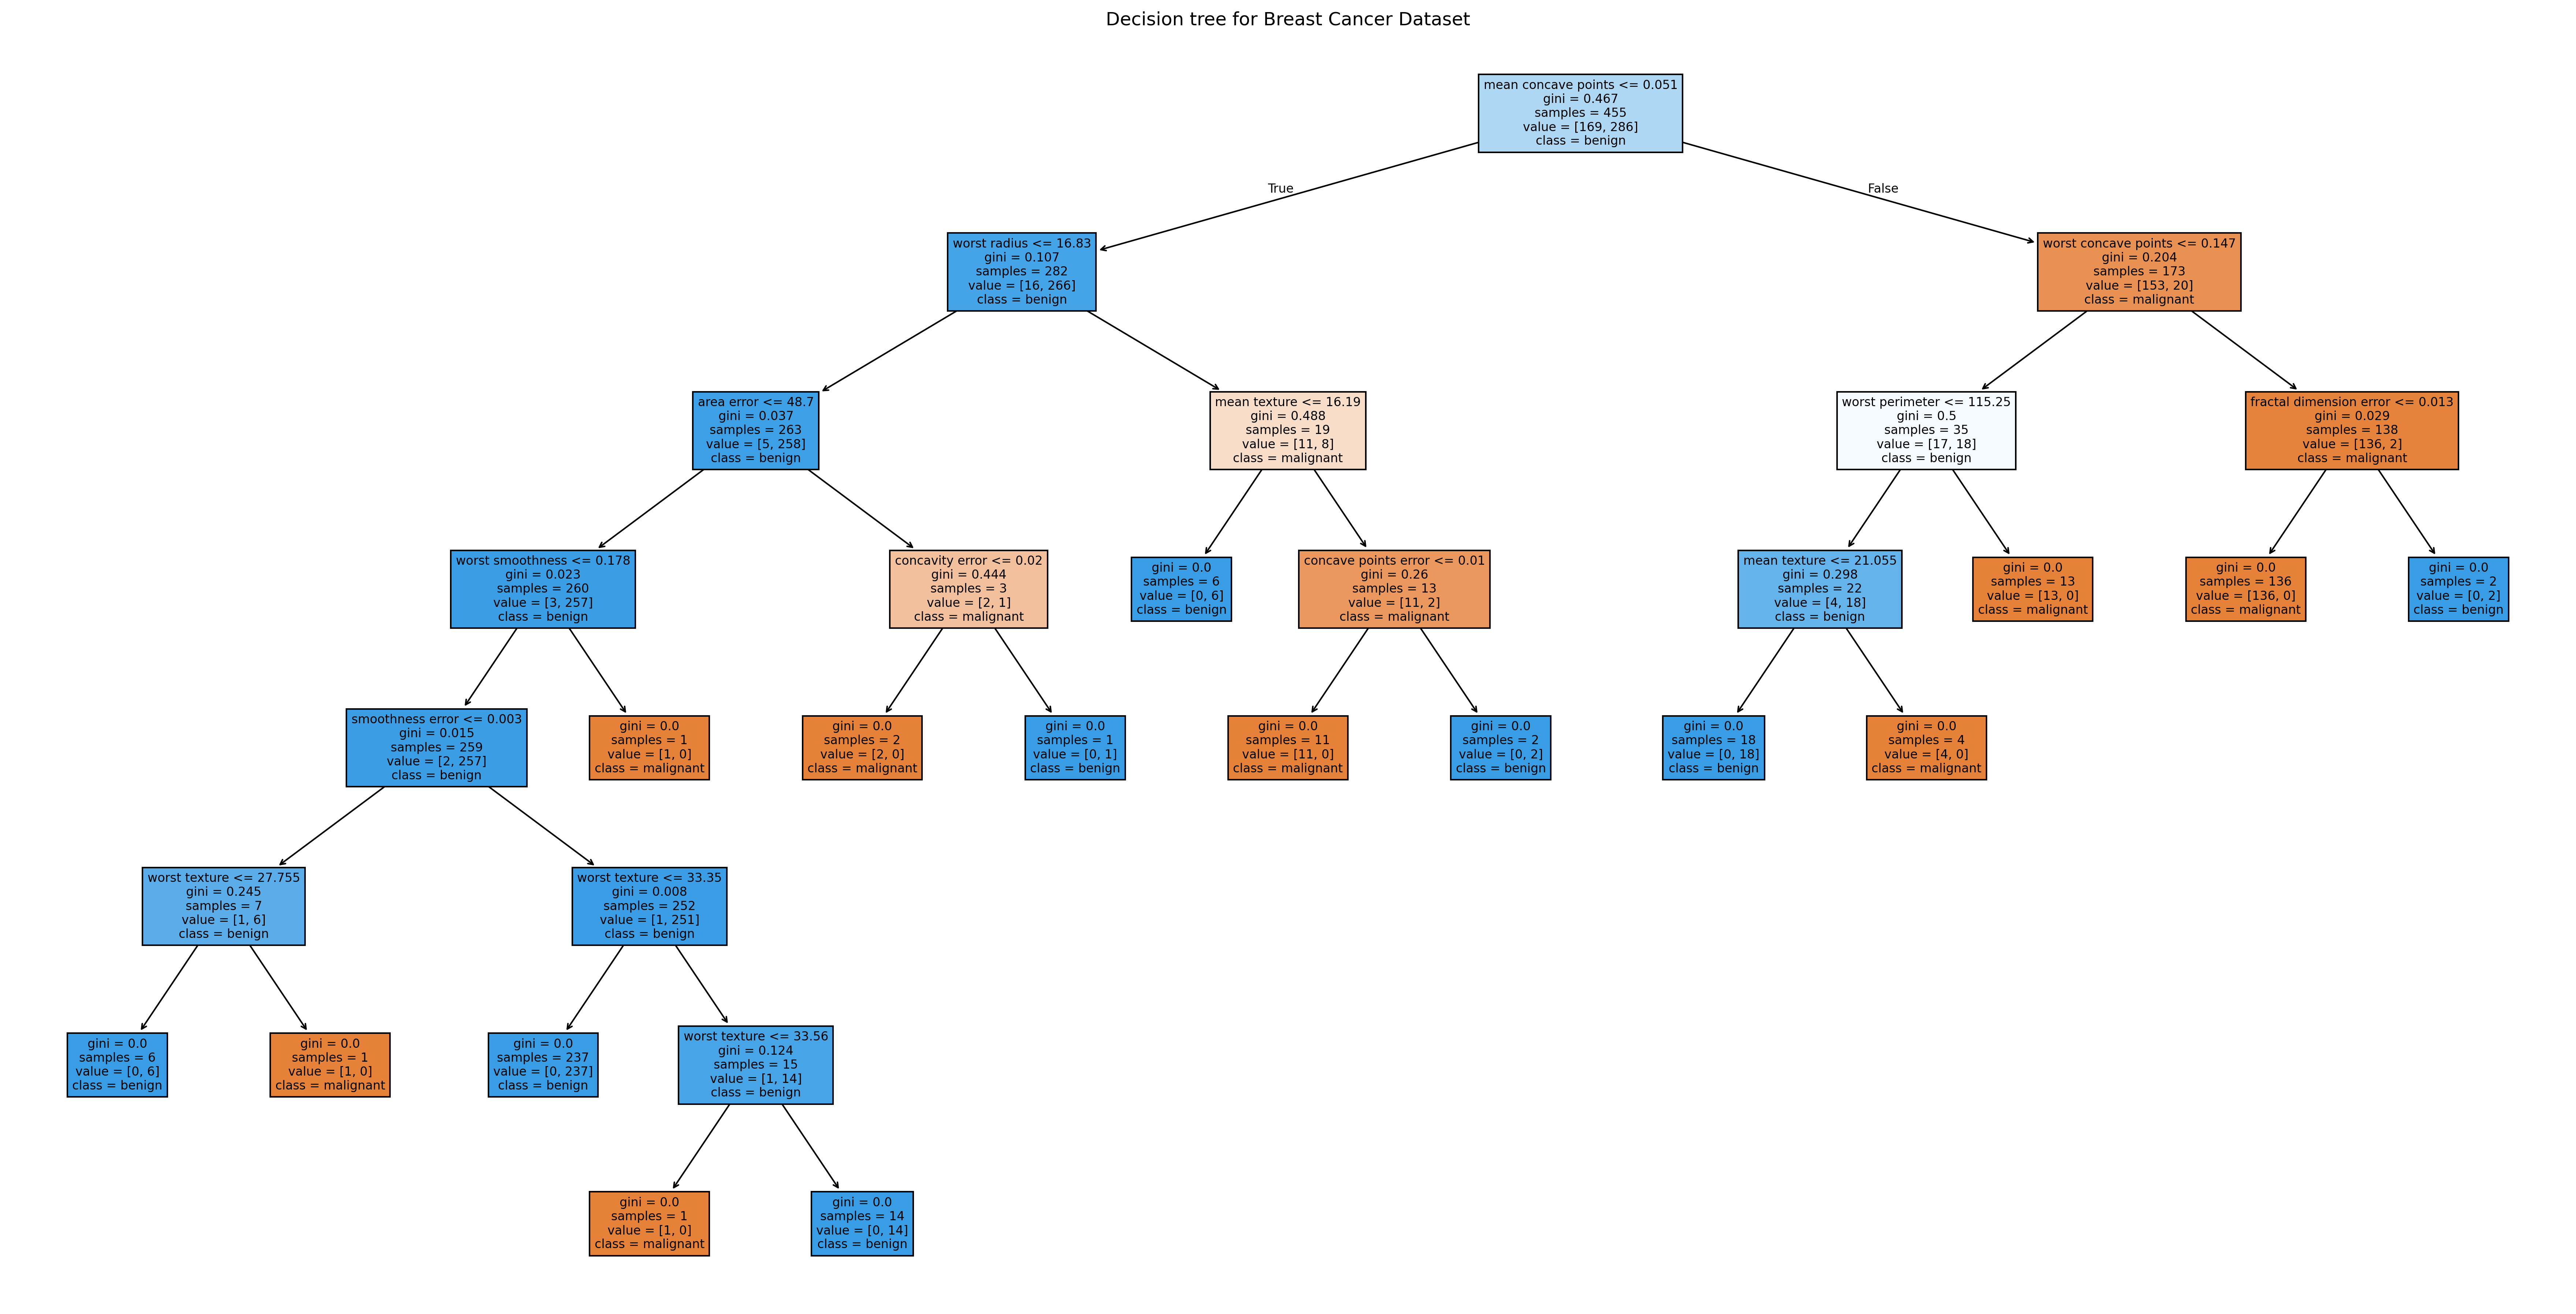

In [7]:
plt.figure(figsize=(30, 15), dpi=300)
plot_tree(
    model,
    feature_names=cancer.feature_names,
    class_names=cancer.target_names,
    filled=True
)
plt.title("Decision tree for Breast Cancer Dataset")
plt.show()